### Building a Basic Chatbot - with LangGraph (GRAPH API)

In [6]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

from langgraph.graph.message import add_messages # these are called a reducers which used to append(add) future messages on it.

In [7]:
class State(TypedDict):
    # Messages have the type "list". The  `add_messages` function 
    # In the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [8]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv()

api_key = os.getenv("GROQ_API_KEY")

if not api_key:
    raise ValueError("GROQ_API_KEY is missing from .env")

In [10]:
import atexit
import ssl
import tempfile
from pathlib import Path

import httpx

# Use Windows' trusted CA store because this environment's certifi bundle fails to parse.
windows_ca_pems = [
    ssl.DER_cert_to_PEM_cert(cert)
    for cert, encoding, trust in ssl.enum_certificates("ROOT")
    if encoding == "x509_asn"
    and (trust is True or "1.3.6.1.5.5.7.3.1" in trust)
]
if not windows_ca_pems:
    raise RuntimeError("No trusted server certificates found in the Windows ROOT store.")

windows_ca_bundle = "".join(windows_ca_pems)
ssl_context = ssl.create_default_context(cadata=windows_ca_bundle)

_ca_bundle_file = tempfile.NamedTemporaryFile(
    mode="w", suffix=".pem", encoding="ascii", delete=False
)
try:
    _ca_bundle_file.write(windows_ca_bundle)
finally:
    _ca_bundle_file.close()

os.environ["REQUESTS_CA_BUNDLE"] = _ca_bundle_file.name
atexit.register(lambda: Path(_ca_bundle_file.name).unlink(missing_ok=True))

http_client = httpx.Client(verify=ssl_context, timeout=30)
http_async_client = httpx.AsyncClient(verify=ssl_context, timeout=30)

In [5]:
print("SSL configured with", len(windows_ca_pems), "Windows trusted CA certificates")

SSL configured with 27 Windows trusted CA certificates


In [9]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    http_client=http_client,
    http_async_client=http_async_client,
)

print(llm.invoke("Hello"))

content='Hello! How can I assist you today?' additional_kwargs={'reasoning_content': 'The user says "Hello". We need to respond appropriately. No special instructions. Just greet back.'} response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.080600749, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.003810571, 'prompt_tokens_details': None, 'queue_time': 0.210855612, 'total_time': 0.08441132}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a13065-296b-7fb3-bb25-c2c5ae69c88e-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning': 21}}


In [11]:
llm = init_chat_model(
    "groq:openai/gpt-oss-120b",
    http_client=http_client,
    http_async_client=http_async_client,
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000248E2AC6BA0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000248E2AC6F90>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), http_client=<httpx.Client object at 0x00000248E28EC050>, http_async_client=<httpx.AsyncClient object at 0x00000248E28EDE80>)

In [12]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [13]:
graph_builder = StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot", chatbot)

# Adding Edge
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph=graph_builder.compile()

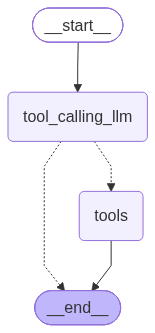

In [19]:
## Visualization the graph

from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [16]:
response = graph.invoke({"messages": "Hi"})

In [ ]:
print (response["messages"])
print (response["messages"][-1].content)


[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='50726a8a-9bfe-47ba-9959-7f08a80b152a'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi". Should greet and ask how can help. Follow policies.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 72, 'total_tokens': 113, 'completion_time': 0.086199797, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003732611, 'prompt_tokens_details': None, 'queue_time': 0.213033918, 'total_time': 0.089932408}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_86dc843b12', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ff3-317c-7943-9f3f-35f5705d95f6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 41, 'total_tokens': 113, 'output_token_details': {'reasoning': 23}})]


In [ ]:
## Insted of using .invoke i am using stream here.
for event in graph.stream({"messages": "Hi, How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing well, thank you. How can I assist you today?


### Chatboat With Tool

In [14]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results = 2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [30]:
## Custom function to use the tool in the graph
def multiple(a: int, b: int) -> int:
    """
    Multiple a and b

    Args:
        a (int): The first number.
        b (int): The second number.

    Returns:
        int: The product of a and b.
    """
    return a*b

In [16]:
tools = [tool, multiple]
llm_with_tools = llm.bind_tools(tools);
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000248E2AC6BA0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000248E2AC6F90>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), http_client=<httpx.Client object at 0x00000248E28EC050>, http_async_client=<httpx.AsyncClient object at 0x00000248E28EDE80>), kwargs={'tools': [{'type'

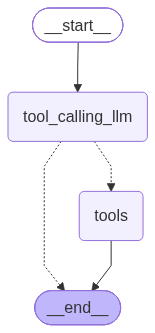

In [22]:
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

## Compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
response = graph.invoke({"messages": "What's the recent ai news"});
response["messages"][-1].content

'{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hellogrowth.ai/en/blog/google-ai-news-october-2026", "title": "Google AI news October 2026 · Hello Growth", "content": "Google had a busy first half of October. Most of the news was about agents: AI that does not just answer, but carries out tasks itself. Below, for each development: what happened, who it matters to and where to read more. Checked on 11 October 2026.\\n\\n## 1. The Gemini agent: one agent for all your work\\n\\nOn 8 October Google Cloud announced the Gemini agent: \\"a single, universal agent for work\\". You give it an objective, and it works in Gmail, Docs, Sheets, Chat and Calendar, but also in Slack and Microsoft 365. A coworker agent gets its own Workspace account with an email address, calendar and Drive, acts under its own name and leaves everything in a log. Under the hood, Gemini picks a model for each job, from Google\'s own models

In [27]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_dedefada-7661-40ce-a4c4-2e31508093d8)
 Call ID: fc_dedefada-7661-40ce-a4c4-2e31508093d8
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hellogrowth.ai/en/blog/google-ai-news-october-2026", "title": "Google AI news October 2026 · Hello Growth", "content": "Google had a busy first half of October. Most of the news was about agents: AI that does not just answer, but carries out tasks itself. Below, for each development: what happened, who it matters to and where to read more. Checked on 11 October 20

In [31]:
response = graph.invoke({"messages": "What's 2 multiply by 3"});
response

{'messages': [HumanMessage(content="What's 2 multiply by 3", additional_kwargs={}, response_metadata={}, id='f109b98c-cc59-486f-8b46-0dabe7a69418'),
  AIMessage(content='2\u202f×\u202f3\u202f=\u202f6.', additional_kwargs={'reasoning_content': 'User asks "What\'s 2 multiply by 3". Simple arithmetic: 2 * 3 = 6. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 351, 'total_tokens': 397, 'completion_time': 0.095894134, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.016363108, 'prompt_tokens_details': None, 'queue_time': 0.414872687, 'total_time': 0.112257242}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a130a5-e03c-7dc3-bf01-b4f24bbbb104-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 351, 'output_tokens': 46, 'total_tokens': 397, 'output_token_details

In [32]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's 2 multiply by 3
================================== Ai Message ==================================

2 × 3 = 6.


In [33]:
response = graph.invoke({"messages": "What's 5 multiply by 4 and then multiply by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's 5 multiply by 4 and then multiply by 10
================================== Ai Message ==================================

5 × 4 = 20, and 20 × 10 = 200. So the result is **200**.


In [34]:
response = graph.invoke({"messages": "Give me recent ai news and then multiply by 5 by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and then multiply by 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_55db8c79-bfa1-4f00-8342-1147ef658139)
 Call ID: fc_55db8c79-bfa1-4f00-8342-1147ef658139
  Args:
    query: AI news October 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/NikeeluGundaofficial/posts/5-big-ai-updates-you-should-know-today-october-7-2026ai-is-moving-beyond-chatbot/1773372201461569", "title": "Nikeelu Gunda", "content": "Log in\n\nLog in\n\nForgotten account?\n\n## Nikeelu Gunda's post\n\n  \n\n[](\n\n### Nikeelu Gunda\n\n4 days ago\n\n4d · Verappa · Sai Abhyankkar, Arivu, Arun Srinivasan

### ReACT Agent Architecture

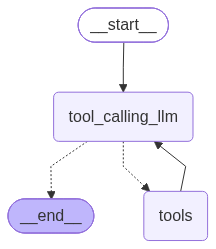

In [35]:
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)

## Compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
response = graph.invoke({"messages": "Give me recent ai news and then multiply by 5 by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and then multiply by 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_336acff5-487c-47c1-90ce-f30a782c7b95)
 Call ID: fc_336acff5-487c-47c1-90ce-f30a782c7b95
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/jonathanjmast/posts/%F0%9D%97%94%F0%9D%97%9C-%F0%9D%97%A1%F0%9D%97%98%F0%9D%97%AA%F0%9D%97%A6-%F0%9D%97%A7%F0%9D%97%9B%F0%9D%97%94%F0%9D%97%A7-%F0%9D%97%A0%F0%9D%97%94%F0%9D%97%A7%F0%9D%97%A7%F0%9D%97%98%F0%9D%97%A5%F0%9D%97%A6-%F0%9D%97%A7%F0%9D%97%A2-%F0%9D%97%98%F0%9D%97%A1%F0%9D%97%A7%F0%9D%97%A5%F0%9

### Adding Memory In Agentic Graph

In [37]:
response = graph.invoke({"messages": "My Name is Karan"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My Name is Karan
================================== Ai Message ==================================

Nice to meet you, Karan! How can I assist you today?


In [38]:
response = graph.invoke({"messages": "What is my name"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t actually know your name—unless you’ve told me before, I don’t have that information. If you’d like me to address you by name, just let me know what it is!
